# Project: Forecasting Approach Evaluation and Recommendation

The board meeting is in two weeks. Your VP of Sales presented a revenue target of **$4.1M per month by December 2026** — 18% year-over-year growth. The number came from pasting a data export into a generative AI tool and asking it to forecast.

Your data engineering team has already audited the VP's original query and found several bugs that inflated recent revenue figures and made the growth trend look steeper than it actually is. They've corrected the issues and handed you a **clean dataset** (`revenue.csv`) with 60 months of monthly revenue from January 2021 through December 2025.

**Your job:** Take the clean data and figure out what the numbers actually say. Build progressively sophisticated forecasts — from simple baselines through classical ARIMA/SARIMAX to neural models and foundation models — and deliver a stakeholder-ready recommendation with prediction intervals that a non-technical executive can act on.

---

## Deliverables

1. This completed notebook with all phases implemented
2. A comparison table showing all models, their December 2026 forecasts, prediction intervals, and accuracy metrics
3. At least three charts: baseline comparison, classical model forecasts with intervals, modern model forecasts
4. A written recommendation (500–1000 words) answering:
   - What is the realistic range for December 2026 revenue?
   - What should the company plan for instead of $4.1M?
   - Which forecasting approach would you recommend for ongoing use, and why?

## Setup

Run this notebook in the project's uv environment. From the project root, `uv sync` installs the exact versions pinned in `uv.lock` (Python 3.12, statsmodels 0.15.0, darts 0.47.0, chronos-forecasting 2.3.2), and `uv run jupyter lab` opens the notebook in that environment. See the README for details.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from darts import TimeSeries
from darts.models import NBEATSModel, ARIMA as DartsARIMA
from darts.metrics import mae, rmse, mape
from darts.utils.likelihood_models import QuantileRegression
import torch
from chronos import BaseChronosPipeline
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

VP_TARGET = 4_100_000
HORIZON = 12  # months ahead (Jan 2026 through Dec 2026)

## Load Data

The clean revenue dataset has been prepared by your data engineering team. It contains monthly revenue from January 2021 through December 2025.

Date range: 2021-01-01 to 2025-12-01
Number of months: 60
Revenue range: $1.89M to $3.83M


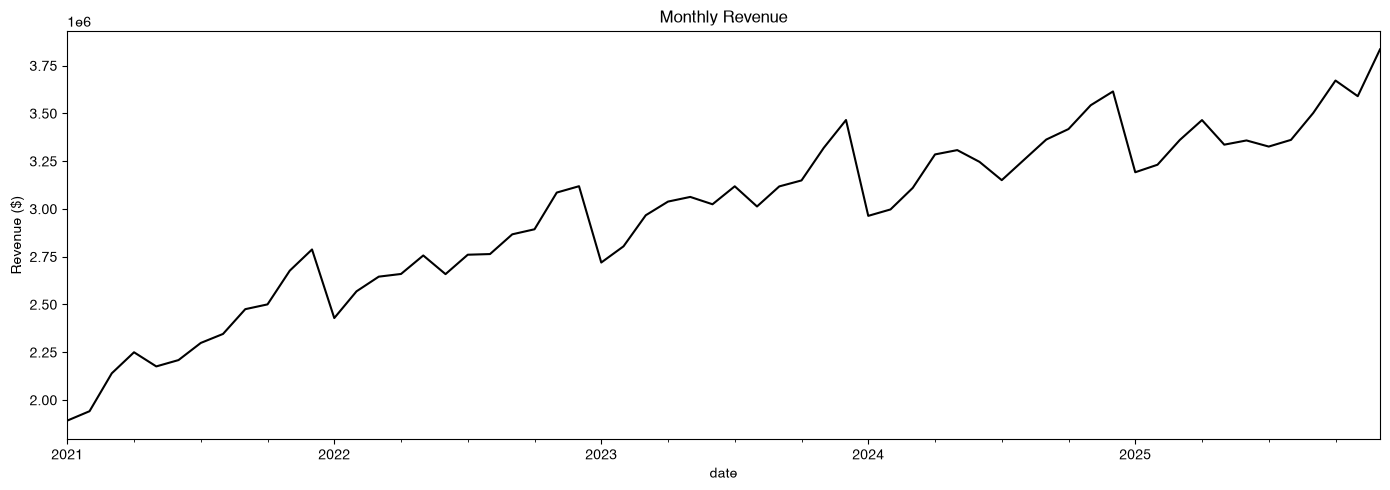

In [2]:
df = pd.read_csv(
    "../data/revenue.csv",
    parse_dates=["date"],
    index_col="date",
)
df.index.freq = "MS"
revenue = df["revenue"]

print(f"Date range: {revenue.index[0].date()} to {revenue.index[-1].date()}")
print(f"Number of months: {len(revenue)}")
print(f"Revenue range: ${revenue.min()/1e6:.2f}M to ${revenue.max()/1e6:.2f}M")

revenue.plot(figsize=(14, 5), color="black", title="Monthly Revenue")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

## Phase 1: Baseline Forecasts

Before reaching for sophisticated models, establish baselines. Compute simple forecasts over a 12-month horizon and compare each to the VP's $4.1M target.

### Helper Functions

The next cell defines four small helpers that every baseline will reuse:

- `naive_forecast` — repeats the last observed value (assumes no trend and no seasonality).
- `moving_average_forecast` — repeats the trailing `window`-month average (smooths short-term noise).
- `trend_forecast` — fits a straight line to the history and extrapolates it (assumes linear growth continues).
- `plot_forecasts` — draws the actuals, every forecast, and the VP target line on one chart.

Each forecast helper returns a `pd.Series` indexed by month-start dates, beginning the month after the last observation.

In [3]:
def naive_forecast(series, horizon):
    """Repeat the last observed value for `horizon` months."""
    last = series.iloc[-1]
    future = pd.date_range(
        start=series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    return pd.Series([last] * horizon, index=future)


def moving_average_forecast(series, window, horizon):
    """Repeat the trailing `window`-month average for `horizon` months."""
    avg = series.iloc[-window:].mean()
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    return pd.Series([avg] * horizon, index=future)


def trend_forecast(series, horizon):
    """Fit a linear trend and extrapolate for `horizon` months."""
    t = np.arange(len(series))
    coeffs = np.polyfit(x=t, y=series.values, deg=1)
    future_t = np.arange(len(series), len(series) + horizon)
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    return pd.Series(np.polyval(coeffs, future_t), index=future)


def plot_forecasts(actuals, forecasts, target=VP_TARGET, title="Forecast Comparison"):
    """Plot actuals and multiple forecast series against the VP target."""
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(actuals.index, actuals / 1e6, color="black", linewidth=1.5, label="Actual")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:red"]
    for i, (name, fc) in enumerate(forecasts.items()):
        ax.plot(fc.index, fc / 1e6, "--", color=colors[i % len(colors)], label=name)
    ax.axhline(
        y=target / 1e6, color="red", linestyle=":", linewidth=2,
        label=f"VP target: ${target/1e6:.1f}M",
    )
    ax.set_ylabel("Revenue ($M)")
    ax.set_title(title)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    return fig

### Generate Baseline Forecasts

Create the naive, 6-month MA, 12-month MA, and linear trend forecasts over the 12-month horizon, then compare each December 2026 forecast to the VP target. The 6-month window tracks the recent revenue level; the 12-month window spans a full year, so it averages out the seasonal pattern.

In [4]:
# Baseline methods, each with a different assumption about the future:
# - Naive: no trend or seasonality; repeats the last month
# - Moving average: smooths out short-term fluctuations
# - Trend: linear growth continues
#
# Moving-average windows: 6 months tracks the recent level;
# 12 months spans a full year, so it averages out the seasonal pattern

# Generate the 12-month (Jan-Dec 2026) baseline forecasts
forecasts = {
    'Naive': naive_forecast(revenue, horizon=HORIZON),
    '6MA': moving_average_forecast(revenue, window=6, horizon=HORIZON),
    '12MA': moving_average_forecast(revenue, window=12, horizon=HORIZON),
    'Trend': trend_forecast(revenue, horizon=HORIZON)
}

# Compare December 2026 forecasts to VP target
for name, fc in forecasts.items():
    dec_2026 = fc.iloc[-1]
    gap = dec_2026 - VP_TARGET
    print(f"{name}: ${dec_2026/1e6:.2f}M (gap: ${gap/1e6:+.2f}M)")

Naive: $3.83M (gap: $-0.27M)
6MA: $3.55M (gap: $-0.55M)
12MA: $3.44M (gap: $-0.66M)
Trend: $3.98M (gap: $-0.12M)


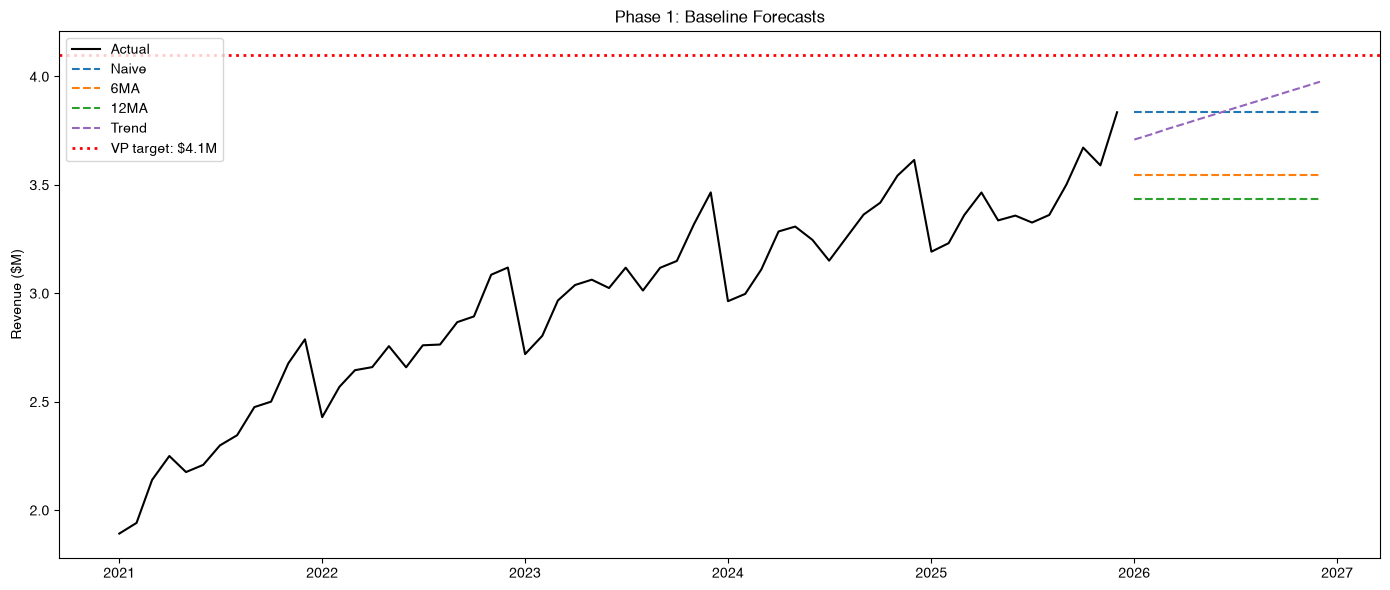

In [5]:
plot_forecasts(revenue, forecasts, VP_TARGET, "Phase 1: Baseline Forecasts");

---

## Phase 2: Classical Models

Fit ARIMA and SARIMAX models. Experiment with different parameter specifications to see which ones converge and produce reasonable forecasts.

### Train/Test Split

Split at December 2024. Train on data through December 2024, test on January 2025 through December 2025.

In [6]:
train = revenue[:'2024-12']
test = revenue['2025-01':]

print(f"Train: {train.index[0]} to {train.index[-1]} ({len(train)} months)")
print(f"Test:  {test.index[0]} to {test.index[-1]} ({len(test)} months)")

Train: 2021-01-01 00:00:00 to 2024-12-01 00:00:00 (48 months)
Test:  2025-01-01 00:00:00 to 2025-12-01 00:00:00 (12 months)


### Phase 2a: ARIMA Parameter Exploration

Start with ARIMA(2,1,1) with a constant trend, then try two alternative **non-seasonal** specifications (seasonality is covered in Phase 2b). If a model fails to converge, try fewer parameters or drop the trend. Compare the candidates by AIC, then evaluate the best one on the test period.

In [7]:
# Start with ARIMA(2,1,1) with trend='c'
arima_211 = SARIMAX(train, order=(2, 1, 1), trend='c').fit(disp=False)
print(f"ARIMA(2,1,1) AIC: {arima_211.aic:.2f}")

ARIMA(2,1,1) AIC: 1258.17


In [8]:
# Try an alternative ARIMA specification: fewer parameters
# ARIMA(0,1,0) with trend='c' is a random walk with drift
arima_alt = SARIMAX(train, order=(0, 1, 0), trend='c').fit(disp=False)
print(f"ARIMA(0,1,0) with trend='c' AIC: {arima_alt.aic:.2f}")

ARIMA(0,1,0) with trend='c' AIC: 1252.18


In [9]:
# Try a third ARIMA specification: different (p,d,q), no trend
# ARIMA(1,1,0) models each month's change as a fraction of the previous month's change
arima_third = SARIMAX(train, order=(1, 1, 0), trend='n').fit(disp=False)
print(f"ARIMA(1,1,0) with trend='n' AIC: {arima_third.aic:.2f}")

ARIMA(1,1,0) with trend='n' AIC: 1255.23


In [10]:
def test_metrics(results, test):
    """Forecast the test period from a fitted model and return (MAE, RMSE)."""
    pred = results.get_forecast(steps=len(test)).predicted_mean
    errors = pred - test
    return np.mean(np.abs(errors)), np.sqrt(np.mean(np.square(errors)))


def compare_models(models, test):
    """Table of convergence, AIC, and test-period MAE/RMSE for fitted statsmodels results."""
    rows = []
    for name, results in models.items():
        model_mae, model_rmse = test_metrics(results, test)
        rows.append({
            "Model": name,
            "Converged": results.mle_retvals["converged"],
            "AIC": results.aic,
            "Test MAE": model_mae,
            "Test RMSE": model_rmse,
        })
    return pd.DataFrame(rows).set_index("Model")


TABLE_FORMAT = {
    "AIC": "{:.2f}".format,
    "Test MAE": "${:,.0f}".format,
    "Test RMSE": "${:,.0f}".format,
}

# Compare convergence, AIC, and test error across the ARIMA models
arima_results = compare_models({
    "ARIMA(2,1,1), trend='c'": arima_211,
    "ARIMA(0,1,0), trend='c'": arima_alt,
    "ARIMA(1,1,0), trend='n'": arima_third,
}, test)
print(arima_results.to_string(formatters=TABLE_FORMAT))

                         Converged     AIC Test MAE Test RMSE
Model                                                        
ARIMA(2,1,1), trend='c'       True 1258.17 $385,184  $398,528
ARIMA(0,1,0), trend='c'       True 1252.18 $417,258  $428,165
ARIMA(1,1,0), trend='n'       True 1255.23 $225,467  $253,431


In [11]:
# Best ARIMA: lowest test error (reasoning in the markdown cell below)
best_arima_name = "ARIMA(1,1,0), trend='n'"
best_arima = arima_third

arima_mae = arima_results.loc[best_arima_name, "Test MAE"]
arima_rmse = arima_results.loc[best_arima_name, "Test RMSE"]

print(f"Best ARIMA: {best_arima_name}")
print(f"Best ARIMA Test MAE: ${arima_mae:,.0f}")
print(f"Best ARIMA Test RMSE: ${arima_rmse:,.0f}")

Best ARIMA: ARIMA(1,1,0), trend='n'
Best ARIMA Test MAE: $225,467
Best ARIMA Test RMSE: $253,431


**Best ARIMA model: ARIMA(1,1,0) with no trend.**

All three models converged. Their AICs fall within about 6 points of each other (1252.18 to 1258.17), and ARIMA(1,1,0) is only about 3 points above the lowest, so AIC gives weak evidence for any one of them. On the 2025 test year, however, ARIMA(1,1,0) roughly halves the error: MAE of about \$225K against \$385K and \$417K for the other two. Since the purpose is forecasting, out-of-sample accuracy decides.

### Phase 2b: SARIMAX Parameter Exploration

Try different SARIMAX specifications with seasonal components.

**Start with:** SARIMAX(1,1,1)(1,1,1,12)

In [12]:
# Start with SARIMAX(1,1,1)(1,1,1,12)
sarimax_1 = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
).fit(disp=False)
print(f"SARIMAX(1,1,1)(1,1,1,12) AIC: {sarimax_1.aic:.2f}")

SARIMAX(1,1,1)(1,1,1,12) AIC: 905.56


In [13]:
# Try an alternative SARIMAX specification
sarimax_2 = SARIMAX(
    train,
    order=(0, 1, 0),
    seasonal_order=(1, 1, 1, 12),
    trend='n'
).fit(disp=False)
print(f"Alternative SARIMAX AIC: {sarimax_2.aic:.2f}")

Alternative SARIMAX AIC: 899.10


In [14]:
# Compare convergence, AIC, and test error across the SARIMAX models
# AIC is only comparable within this group, not against the ARIMA models above,
# because seasonal differencing changes the data the likelihood is computed on.
sarimax_results = compare_models({
    "SARIMAX(1,1,1)(1,1,1,12)": sarimax_1,
    "SARIMAX(0,1,0)(1,1,1,12)": sarimax_2,
}, test)
print(sarimax_results.to_string(formatters=TABLE_FORMAT))

                          Converged    AIC Test MAE Test RMSE
Model                                                        
SARIMAX(1,1,1)(1,1,1,12)      False 905.56  $66,977   $83,140
SARIMAX(0,1,0)(1,1,1,12)       True 899.10  $68,335   $85,666


In [15]:
# Best SARIMAX: converged, lowest AIC, near-identical test error (reasoning below)
best_sarimax_name = "SARIMAX(0,1,0)(1,1,1,12)"
best_sarimax = sarimax_2

sarimax_mae = sarimax_results.loc[best_sarimax_name, "Test MAE"]
sarimax_rmse = sarimax_results.loc[best_sarimax_name, "Test RMSE"]

print(f"Best SARIMAX: {best_sarimax_name}")
print(f"Best SARIMAX Test MAE: ${sarimax_mae:,.0f}")
print(f"Best SARIMAX Test RMSE: ${sarimax_rmse:,.0f}")

Best SARIMAX: SARIMAX(0,1,0)(1,1,1,12)
Best SARIMAX Test MAE: $68,335
Best SARIMAX Test RMSE: $85,666


**Best SARIMAX model: SARIMAX(0,1,0)(1,1,1,12).**

The required starting model, SARIMAX(1,1,1)(1,1,1,12), did **not** converge, so its parameter estimates are unreliable even though its test error is similar. The alternative converged, has the lower AIC (899.10 vs. 905.56), and nearly the same test error (MAE of about \$68K vs. \$67K). Both seasonal models are far more accurate on 2025 than any non-seasonal ARIMA, which points to a strong yearly pattern in revenue.

### Phase 2c: Residual Diagnostics

A well-specified model leaves residuals that look like random noise. The Ljung-Box test (lag 12) checks for leftover autocorrelation, and the Jarque-Bera test checks normality.

The first `d + D×s` residuals are skipped (1 for the ARIMA, 13 for the SARIMAX). With differencing, statsmodels has no earlier value to difference against, so those first residuals equal the raw starting level and would swamp both tests.

In [16]:
def residual_diagnostics(results, label):
    """Print Ljung-Box (lag 12) and Jarque-Bera p-values, skipping the differencing burn-in."""
    model = results.model
    burn_in = model.k_diff + model.k_seasonal_diff * model.seasonal_periods
    resid = results.resid.iloc[burn_in:]

    lb_pvalue = acorr_ljungbox(resid, lags=[12])["lb_pvalue"].iloc[0]
    _, jb_pvalue = stats.jarque_bera(resid)

    print(f"{label} (first {burn_in} residuals skipped)")
    print(f"  AIC: {results.aic:.2f}")
    print(f"  Ljung-Box p-value (lag 12): {lb_pvalue:.4f}  (< 0.05 means leftover autocorrelation)")
    print(f"  Jarque-Bera p-value:        {jb_pvalue:.4f}  (< 0.05 means residuals are not normal)")


# ARIMA diagnostics
residual_diagnostics(best_arima, best_arima_name)

ARIMA(1,1,0), trend='n' (first 1 residuals skipped)
  AIC: 1255.23
  Ljung-Box p-value (lag 12): 0.0003  (< 0.05 means leftover autocorrelation)
  Jarque-Bera p-value:        0.0000  (< 0.05 means residuals are not normal)


In [17]:
# SARIMAX diagnostics
residual_diagnostics(best_sarimax, best_sarimax_name)

SARIMAX(0,1,0)(1,1,1,12) (first 13 residuals skipped)
  AIC: 899.10
  Ljung-Box p-value (lag 12): 0.4281  (< 0.05 means leftover autocorrelation)
  Jarque-Bera p-value:        0.3746  (< 0.05 means residuals are not normal)


### Phase 2d: Refit on Full Data and Forecast to December 2026

The best ARIMA and SARIMAX specifications are refit on all 60 months. Each forecast reports a **95% interval**, plus an 80% interval. 80% is the widest level every model in this notebook can produce (Chronos-Bolt cannot go wider), so it is the level used to compare them.

In [18]:
# Refit the best ARIMA on the full dataset (same order and trend as best_arima)
final_arima = SARIMAX(
    revenue,
    order=(1, 1, 0),
    trend='n',
).fit(disp=False)

arima_fc = final_arima.get_forecast(steps=HORIZON)
arima_mean = arima_fc.predicted_mean
arima_ci = arima_fc.conf_int(alpha=0.05)    # 95% interval
arima_ci80 = arima_fc.conf_int(alpha=0.20)  # 80% interval, comparable across all models

fc_index = pd.date_range('2026-01-01', periods=HORIZON, freq='MS')
arima_mean.index = fc_index
arima_ci.index = fc_index
arima_ci80.index = fc_index

arima_dec_2026 = arima_mean.iloc[-1]
arima_lower, arima_upper = arima_ci.iloc[-1]
arima_lower80, arima_upper80 = arima_ci80.iloc[-1]

print(f"ARIMA Dec 2026: ${arima_dec_2026/1e6:.2f}M (gap vs target: ${(arima_dec_2026 - VP_TARGET)/1e6:+.2f}M)")
print(f"95% interval: [${arima_lower/1e6:.2f}M, ${arima_upper/1e6:.2f}M]")
print(f"80% interval: [${arima_lower80/1e6:.2f}M, ${arima_upper80/1e6:.2f}M]")

ARIMA Dec 2026: $3.83M (gap vs target: $-0.27M)
95% interval: [$2.81M, $4.86M]
80% interval: [$3.16M, $4.50M]


In [19]:
# Refit the best SARIMAX on the full dataset (same specification as best_sarimax)
final_sarimax = SARIMAX(
    revenue,
    order=(0, 1, 0),
    seasonal_order=(1, 1, 1, 12),
    trend='n',
).fit(disp=False)

sarimax_fc = final_sarimax.get_forecast(steps=HORIZON)
sarimax_mean = sarimax_fc.predicted_mean
sarimax_ci = sarimax_fc.conf_int(alpha=0.05)    # 95% interval
sarimax_ci80 = sarimax_fc.conf_int(alpha=0.20)  # 80% interval, comparable across all models

sarimax_mean.index = fc_index
sarimax_ci.index = fc_index
sarimax_ci80.index = fc_index

sarimax_dec_2026 = sarimax_mean.iloc[-1]
sarimax_lower, sarimax_upper = sarimax_ci.iloc[-1]
sarimax_lower80, sarimax_upper80 = sarimax_ci80.iloc[-1]

print(f"SARIMAX Dec 2026: ${sarimax_dec_2026/1e6:.2f}M (gap vs target: ${(sarimax_dec_2026 - VP_TARGET)/1e6:+.2f}M)")
print(f"95% interval: [${sarimax_lower/1e6:.2f}M, ${sarimax_upper/1e6:.2f}M]")
print(f"80% interval: [${sarimax_lower80/1e6:.2f}M, ${sarimax_upper80/1e6:.2f}M]")

SARIMAX Dec 2026: $3.98M (gap vs target: $-0.12M)
95% interval: [$3.25M, $4.70M]
80% interval: [$3.50M, $4.45M]


In [20]:
# Calculate probability of reaching $4.1M

def prob_above_target(mean, upper_ci, target, alpha=0.05):
    """Probability that a normally distributed forecast exceeds target.

    Backs out the standard error from the upper bound of a (1 - alpha) interval.
    """
    z_crit = stats.norm.ppf(1 - alpha / 2)
    se = (upper_ci - mean) / z_crit
    z = (target - mean) / se
    return 1 - stats.norm.cdf(z)

arima_prob = prob_above_target(arima_dec_2026, arima_upper, VP_TARGET, alpha=0.05)
sarimax_prob = prob_above_target(sarimax_dec_2026, sarimax_upper, VP_TARGET, alpha=0.05)

print(f"P(ARIMA Dec 2026 > $4.1M)   = {arima_prob:.1%}")
print(f"P(SARIMAX Dec 2026 > $4.1M) = {sarimax_prob:.1%}")

P(ARIMA Dec 2026 > $4.1M)   = 30.5%
P(SARIMAX Dec 2026 > $4.1M) = 36.9%


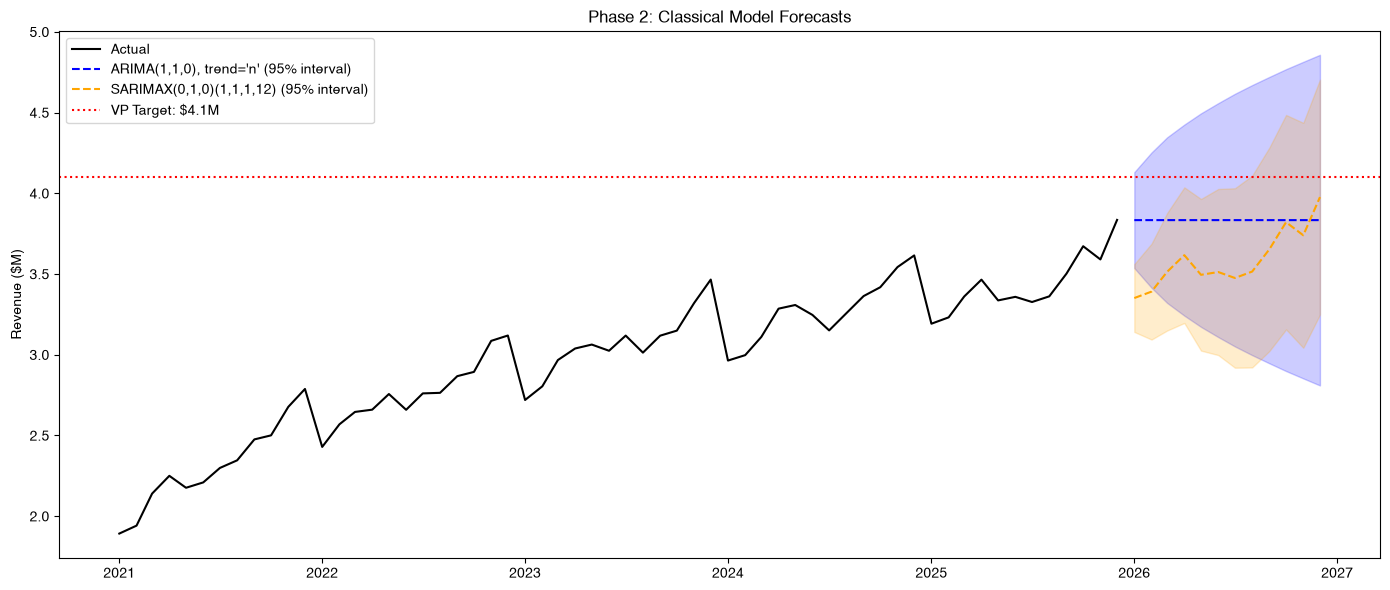

In [21]:
# Plot with 95% prediction intervals
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(revenue.index, revenue / 1e6, 'k-', label='Actual')

ax.plot(fc_index, arima_mean / 1e6, 'b--', label=f'{best_arima_name} (95% interval)')
ax.fill_between(fc_index, arima_ci.iloc[:, 0] / 1e6, arima_ci.iloc[:, 1] / 1e6,
                color='blue', alpha=0.2)

ax.plot(fc_index, sarimax_mean / 1e6, 'orange', linestyle='--', label=f'{best_sarimax_name} (95% interval)')
ax.fill_between(fc_index, sarimax_ci.iloc[:, 0] / 1e6, sarimax_ci.iloc[:, 1] / 1e6,
                color='orange', alpha=0.2)

ax.axhline(y=VP_TARGET / 1e6, color='r', linestyle=':', label='VP Target: $4.1M')

ax.set_ylabel('Revenue ($M)')
ax.set_title('Phase 2: Classical Model Forecasts')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

---

## Phase 3: Modern Models

Train N-BEATS, run a zero-shot Chronos forecast, and fit a Darts ARIMA(2,1,1) baseline. Each model is scored by training on data through December 2024 and forecasting 2025; the December 2026 forecast then uses all 60 months.

In [22]:
ts = TimeSeries.from_dataframe(
    df.reset_index(), 
    time_col='date', 
    value_cols='revenue', 
    freq='MS'
)

train_ts, test_ts = ts.split_before(pd.Timestamp('2025-01-01'))

print(f"Train: {len(train_ts)} months")
print(f"Test: {len(test_ts)} months")

Train: 48 months
Test: 12 months


### N-BEATS (neural network)

N-BEATS is trained with quantile regression so it can produce prediction intervals. The evaluation model is fit on the training set and scored on all of 2025. For the December 2026 forecast, the **same configuration** is refit on all 60 months, mirroring the ARIMA/SARIMAX refit in Phase 2d.

`input_chunk_length=24` leaves 13 training windows inside the 48 training months, because each window needs 24 input months plus 12 output months.

In [23]:
nbeats_config = dict(
    input_chunk_length=24,
    output_chunk_length=12,
    n_epochs=100,
    likelihood=QuantileRegression([0.025, 0.1, 0.5, 0.9, 0.975]),
    random_state=42,
    pl_trainer_kwargs={"accelerator": "cpu", "enable_progress_bar": False},
)

# Evaluate: fit on the training set, predict the entire test set (2025)
nbeats_eval = NBEATSModel(**nbeats_config)
nbeats_eval.fit(train_ts)

nbeats_pred = nbeats_eval.predict(len(test_ts), series=train_ts, num_samples=100).quantile(0.5)
nbeats_mae = mae(test_ts, nbeats_pred)
nbeats_rmse = rmse(test_ts, nbeats_pred)

print(f"N-BEATS Test MAE: ${nbeats_mae:,.0f}")
print(f"N-BEATS Test RMSE: ${nbeats_rmse:,.0f}")

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ criterion       │ MSELoss          │      0 │ train │     0 │
│ 1 │ train_criterion │ MSELoss          │      0 │ train │     0 │
│ 2 │ val_criterion   │ MSELoss          │      0 │ train │     0 │
│ 3 │ train_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ val_metrics     │ MetricCollection │      0 │ train │     0 │
│ 5 │ stacks          │ ModuleList       │  6.4 M │ train │     0 │
└───┴─────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 6.3 M                                                                                            
Non-trainable params: 1.4 K                                                                                        
Total params: 6.4 M                                                                                                
Total estimated model params size (MB): 50.808                                                                     
Modules in train mode: 396                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=100` reached.


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


N-BEATS Test MAE: $153,545
N-BEATS Test RMSE: $168,146


In [24]:
# Forecast: refit the same configuration on all 60 months, then draw 100 samples
nbeats = NBEATSModel(**nbeats_config)
nbeats.fit(ts)
nbeats_fc = nbeats.predict(n=HORIZON, series=ts, num_samples=100)

nbeats_dec_2026 = nbeats_fc.quantile(0.5).values()[-1, 0]
nbeats_lower = nbeats_fc.quantile(0.025).values()[-1, 0]
nbeats_upper = nbeats_fc.quantile(0.975).values()[-1, 0]
nbeats_lower80 = nbeats_fc.quantile(0.1).values()[-1, 0]
nbeats_upper80 = nbeats_fc.quantile(0.9).values()[-1, 0]

# Share of the 100 December 2026 samples that exceed the target
nbeats_prob = (nbeats_fc.all_values()[-1, 0, :] > VP_TARGET).mean()

print(f"N-BEATS Dec 2026 (median of 100 samples): ${nbeats_dec_2026/1e6:.2f}M "
      f"(gap vs target: ${(nbeats_dec_2026 - VP_TARGET)/1e6:+.2f}M)")
print(f"95% interval: [${nbeats_lower/1e6:.2f}M, ${nbeats_upper/1e6:.2f}M]")
print(f"80% interval: [${nbeats_lower80/1e6:.2f}M, ${nbeats_upper80/1e6:.2f}M]")
print(f"Samples above $4.1M: {nbeats_prob:.0%}")

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ criterion       │ MSELoss          │      0 │ train │     0 │
│ 1 │ train_criterion │ MSELoss          │      0 │ train │     0 │
│ 2 │ val_criterion   │ MSELoss          │      0 │ train │     0 │
│ 3 │ train_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ val_metrics     │ MetricCollection │      0 │ train │     0 │
│ 5 │ stacks          │ ModuleList       │  6.4 M │ train │     0 │
└───┴─────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 6.3 M                                                                                            
Non-trainable params: 1.4 K                                                                                        
Total params: 6.4 M                                                                                                
Total estimated model params size (MB): 50.808                                                                     
Modules in train mode: 396                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=100` reached.


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


N-BEATS Dec 2026 (median of 100 samples): $3.90M (gap vs target: $-0.20M)
95% interval: [$3.50M, $4.18M]
80% interval: [$3.66M, $4.12M]
Samples above $4.1M: 13%


### Chronos zero-shot forecast (`amazon/chronos-bolt-small`)

As the rubric specifies, this step uses the pretrained `amazon/chronos-bolt-small` model. Chronos-Bolt has a different architecture from Chronos-2, and darts' `Chronos2Model` (darts 0.47.0) cannot load it, so it runs through Amazon's official `chronos-forecasting` package (2.3.2).

The model is zero-shot: it is never trained on this data, so fitting to the training set means giving it the training months as context. It is scored with data through December 2024 as context, then forecasts December 2026 with all 60 months as context.

**Interval level:** Chronos-Bolt predicts nine fixed percentiles, from the 10th to the 90th, so its widest interval is **80%**. Levels outside that range, such as 5% or 95%, are capped at the 10th and 90th percentiles. This is why the models are compared at 80%.

In [25]:
chronos = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-small",
    device_map="cpu",
    dtype=torch.float32,
)


def chronos_predict(context, horizon):
    """Zero-shot forecast; returns the 10th, 50th, and 90th percentiles by month."""
    quantiles, _ = chronos.predict_quantiles(
        torch.tensor(context.values, dtype=torch.float32),
        prediction_length=horizon,
        quantile_levels=[0.1, 0.5, 0.9],  # widest range Chronos-Bolt supports
    )
    index = pd.date_range(context.index[-1] + pd.DateOffset(months=1), periods=horizon, freq="MS")
    return pd.DataFrame(quantiles[0].numpy(), index=index, columns=["q10", "q50", "q90"])


# Evaluate: training set (through December 2024) as context, predict the entire test set (2025)
chronos_test = chronos_predict(train, len(test))
chronos_errors = chronos_test["q50"] - test
chronos_mae = np.mean(np.abs(chronos_errors))
chronos_rmse = np.sqrt(np.mean(np.square(chronos_errors)))

print(f"Chronos-Bolt Test MAE: ${chronos_mae:,.0f}")
print(f"Chronos-Bolt Test RMSE: ${chronos_rmse:,.0f}")

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt Test MAE: $184,870
Chronos-Bolt Test RMSE: $204,120


In [26]:
# Forecast: all 60 months as context, predict January through December 2026
chronos_fc = chronos_predict(revenue, HORIZON)

chronos_dec_2026 = chronos_fc["q50"].iloc[-1]
chronos_lower80 = chronos_fc["q10"].iloc[-1]
chronos_upper80 = chronos_fc["q90"].iloc[-1]

# Approximate: assumes a symmetric normal distribution around the median
chronos_prob = prob_above_target(chronos_dec_2026, chronos_upper80, VP_TARGET, alpha=0.20)

print(f"Chronos-Bolt Dec 2026: ${chronos_dec_2026/1e6:.2f}M "
      f"(gap vs target: ${(chronos_dec_2026 - VP_TARGET)/1e6:+.2f}M)")
print(f"80% interval: [${chronos_lower80/1e6:.2f}M, ${chronos_upper80/1e6:.2f}M]")
print(f"P(Dec 2026 > $4.1M), approx.: {chronos_prob:.1%}")

Chronos-Bolt Dec 2026: $3.99M (gap vs target: $-0.11M)
80% interval: [$3.46M, $4.44M]
P(Dec 2026 > $4.1M), approx.: 38.1%


### Darts ARIMA(2,1,1) baseline

An ARIMA(2,1,1) fit with Darts, so the modern models can be compared against a classical baseline built the same way. It is fit on the training set and scored on 2025, then forecasts December 2026 using all 60 months as history. Unlike the Phase 2a ARIMA(2,1,1), it has no constant term.

In [27]:
darts_arima = DartsARIMA(p=2, d=1, q=1, random_state=42)  # seed makes the 100 samples reproducible
darts_arima.fit(train_ts)

# Evaluate: predict the entire test set (2025)
darts_arima_pred = darts_arima.predict(len(test_ts))
darts_arima_mae = mae(test_ts, darts_arima_pred)
darts_arima_rmse = rmse(test_ts, darts_arima_pred)

# Forecast: all 60 months as history, 100 samples for the intervals
darts_arima_fc = darts_arima.predict(HORIZON, series=ts, num_samples=100)

darts_arima_dec_2026 = darts_arima_fc.quantile(0.5).values()[-1, 0]
darts_arima_lower = darts_arima_fc.quantile(0.025).values()[-1, 0]
darts_arima_upper = darts_arima_fc.quantile(0.975).values()[-1, 0]
darts_arima_lower80 = darts_arima_fc.quantile(0.1).values()[-1, 0]
darts_arima_upper80 = darts_arima_fc.quantile(0.9).values()[-1, 0]

# Share of the 100 December 2026 samples that exceed the target
darts_arima_prob = (darts_arima_fc.all_values()[-1, 0, :] > VP_TARGET).mean()

print(f"Darts ARIMA Test MAE: ${darts_arima_mae:,.0f}")
print(f"Darts ARIMA Test RMSE: ${darts_arima_rmse:,.0f}")
print(f"Darts ARIMA Dec 2026: ${darts_arima_dec_2026/1e6:.2f}M "
      f"(gap vs target: ${(darts_arima_dec_2026 - VP_TARGET)/1e6:+.2f}M)")
print(f"95% interval: [${darts_arima_lower/1e6:.2f}M, ${darts_arima_upper/1e6:.2f}M]")
print(f"80% interval: [${darts_arima_lower80/1e6:.2f}M, ${darts_arima_upper80/1e6:.2f}M]")
print(f"Samples above $4.1M: {darts_arima_prob:.0%}")

Darts ARIMA Test MAE: $360,237
Darts ARIMA Test RMSE: $376,550
Darts ARIMA Dec 2026: $4.19M (gap vs target: $+0.09M)
95% interval: [$3.32M, $5.05M]
80% interval: [$3.65M, $4.74M]
Samples above $4.1M: 58%


### Modern Model Forecasts vs. the $4.1M Target

Shaded bands are 80% intervals (10th to 90th percentile), the widest level all three models can produce.

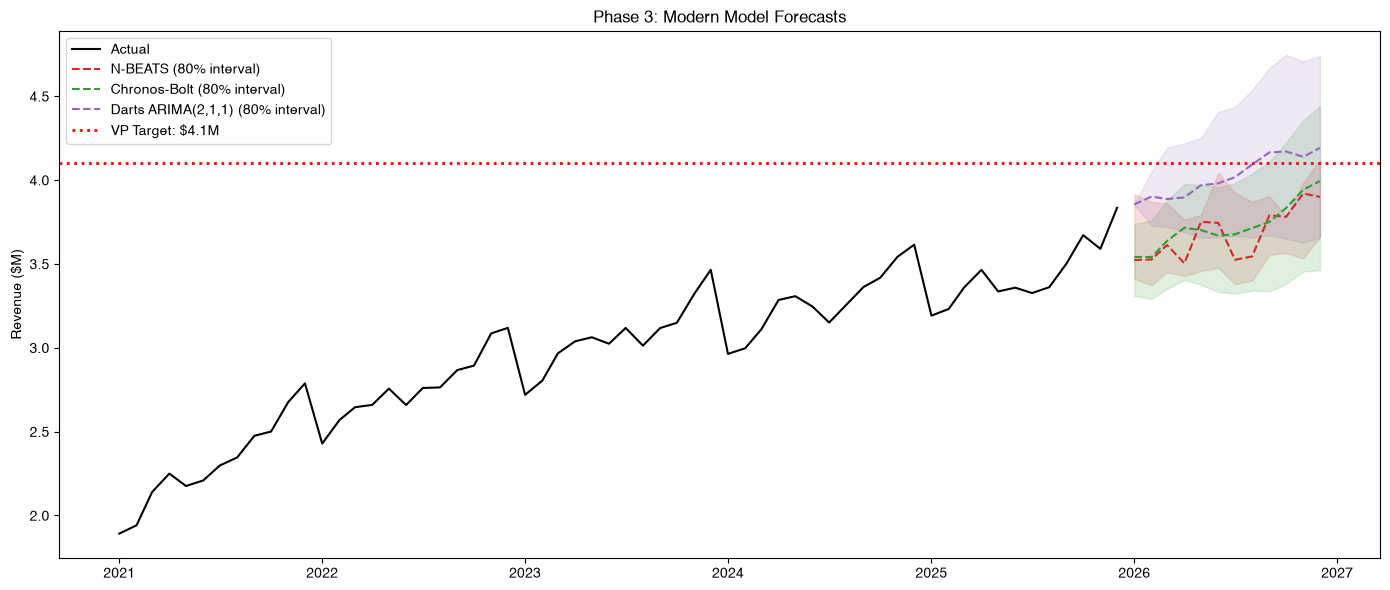

In [28]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(revenue.index, revenue / 1e6, color='black', label='Actual')

# label: (dates, median, lower, upper, color)
modern_forecasts = {
    'N-BEATS (80% interval)': (
        nbeats_fc.time_index, nbeats_fc.quantile(0.5).values().ravel(),
        nbeats_fc.quantile(0.1).values().ravel(), nbeats_fc.quantile(0.9).values().ravel(), 'tab:red'),
    'Chronos-Bolt (80% interval)': (
        chronos_fc.index, chronos_fc['q50'].values,
        chronos_fc['q10'].values, chronos_fc['q90'].values, 'tab:green'),
    'Darts ARIMA(2,1,1) (80% interval)': (
        darts_arima_fc.time_index, darts_arima_fc.quantile(0.5).values().ravel(),
        darts_arima_fc.quantile(0.1).values().ravel(), darts_arima_fc.quantile(0.9).values().ravel(), 'tab:purple'),
}
for label, (dates, median, lower, upper, color) in modern_forecasts.items():
    ax.plot(dates, median / 1e6, '--', color=color, label=label)
    ax.fill_between(dates, lower / 1e6, upper / 1e6, color=color, alpha=0.15)

ax.axhline(y=VP_TARGET / 1e6, color='r', linestyle=':', linewidth=2, label='VP Target: $4.1M')

ax.set_ylabel('Revenue ($M)')
ax.set_title('Phase 3: Modern Model Forecasts')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

---

## Phase 4: Comparison and Recommendation

In [29]:
# Baselines: re-forecast 2025 from the training data so their test error is comparable
baseline_test = {
    'Naive': naive_forecast(train, horizon=len(test)),
    '6MA': moving_average_forecast(train, window=6, horizon=len(test)),
    '12MA': moving_average_forecast(train, window=12, horizon=len(test)),
    'Trend': trend_forecast(train, horizon=len(test)),
}

rows = []
for name, fc in forecasts.items():
    errors = baseline_test[name].values - test.values
    rows.append({
        "Model": name,
        "Dec 2026 Forecast": fc.iloc[-1],
        "Test MAE": np.mean(np.abs(errors)),
        "Test RMSE": np.sqrt(np.mean(np.square(errors))),
    })

rows += [
    {"Model": best_arima_name, "Dec 2026 Forecast": arima_dec_2026,
     "95% Lower": arima_lower, "95% Upper": arima_upper,
     "80% Lower": arima_lower80, "80% Upper": arima_upper80,
     "Test MAE": arima_mae, "Test RMSE": arima_rmse, "P(Reach $4.1M)": arima_prob},
    {"Model": best_sarimax_name, "Dec 2026 Forecast": sarimax_dec_2026,
     "95% Lower": sarimax_lower, "95% Upper": sarimax_upper,
     "80% Lower": sarimax_lower80, "80% Upper": sarimax_upper80,
     "Test MAE": sarimax_mae, "Test RMSE": sarimax_rmse, "P(Reach $4.1M)": sarimax_prob},
    {"Model": "N-BEATS", "Dec 2026 Forecast": nbeats_dec_2026,
     "95% Lower": nbeats_lower, "95% Upper": nbeats_upper,
     "80% Lower": nbeats_lower80, "80% Upper": nbeats_upper80,
     "Test MAE": nbeats_mae, "Test RMSE": nbeats_rmse, "P(Reach $4.1M)": nbeats_prob},
    {"Model": "Chronos-Bolt (zero-shot)", "Dec 2026 Forecast": chronos_dec_2026,
     "80% Lower": chronos_lower80, "80% Upper": chronos_upper80,
     "Test MAE": chronos_mae, "Test RMSE": chronos_rmse, "P(Reach $4.1M)": chronos_prob},
    {"Model": "Darts ARIMA(2,1,1)", "Dec 2026 Forecast": darts_arima_dec_2026,
     "95% Lower": darts_arima_lower, "95% Upper": darts_arima_upper,
     "80% Lower": darts_arima_lower80, "80% Upper": darts_arima_upper80,
     "Test MAE": darts_arima_mae, "Test RMSE": darts_arima_rmse, "P(Reach $4.1M)": darts_arima_prob},
]

columns = ["Dec 2026 Forecast", "Gap vs $4.1M", "95% Lower", "95% Upper",
           "80% Lower", "80% Upper", "Test MAE", "Test RMSE", "P(Reach $4.1M)"]
comparison_df = pd.DataFrame(rows).set_index("Model")
comparison_df["Gap vs $4.1M"] = comparison_df["Dec 2026 Forecast"] - VP_TARGET
comparison_df = comparison_df[columns]


def fmt_millions(v, decimals=2, sign=""):
    return "—" if pd.isna(v) else f"${v/1e6:{sign}.{decimals}f}M"


formatters = {c: fmt_millions for c in ["Dec 2026 Forecast", "95% Lower", "95% Upper", "80% Lower", "80% Upper"]}
formatters["Gap vs $4.1M"] = lambda v: fmt_millions(v, sign="+")
formatters["Test MAE"] = lambda v: fmt_millions(v, decimals=3)
formatters["Test RMSE"] = lambda v: fmt_millions(v, decimals=3)
formatters["P(Reach $4.1M)"] = lambda v: "—" if pd.isna(v) else f"{v:.0%}"

print(comparison_df.to_string(formatters=formatters, na_rep="—"))

                         Dec 2026 Forecast Gap vs $4.1M 95% Lower 95% Upper 80% Lower 80% Upper Test MAE Test RMSE P(Reach $4.1M)
Model                                                                                                                            
Naive                               $3.83M      $-0.27M         —         —         —         —  $0.225M   $0.253M              —
6MA                                 $3.55M      $-0.55M         —         —         —         —  $0.140M   $0.184M              —
12MA                                $3.44M      $-0.66M         —         —         —         —  $0.184M   $0.243M              —
Trend                               $3.98M      $-0.12M         —         —         —         —  $0.271M   $0.291M              —
ARIMA(1,1,0), trend='n'             $3.83M      $-0.27M    $2.81M    $4.86M    $3.16M    $4.50M  $0.225M   $0.253M            31%
SARIMAX(0,1,0)(1,1,1,12)            $3.98M      $-0.12M    $3.25M    $4.70M    $3.50M    $

**How to read the table**

- **95% bounds** are shown where the model can produce them. Chronos-Bolt cannot produce a 95% interval, so its 95% columns are blank.
- **80% bounds** (10th to 90th percentile) are shown for every model with intervals. 80% is the widest level Chronos-Bolt supports, so it is the one level at which all five models can be compared. With 100 samples it is also steadier than 95% for N-BEATS and Darts ARIMA, with about 10 samples in each tail instead of 2 or 3.
- **Baselines** are point forecasts only, with no interval or probability.
- **P(Reach \$4.1M):** ARIMA and SARIMAX use a normal distribution backed out of the 95% interval (any interval level gives the same answer). N-BEATS and Darts ARIMA use the share of 100 simulated values above \$4.1M. Chronos-Bolt uses a normal approximation from its 80% interval, so treat it as rough.
- **Test MAE / RMSE** come from forecasting January to December 2025 using only data through December 2024.
- **N-BEATS' 95% bounds are unreliable.** With only 48 to 60 months of training data, its outermost quantiles are poorly learned, and 100 samples put only 2 or 3 values in each tail. Darts ARIMA's 95% bounds also rest on only 100 samples; its sampling is seeded, so the results are reproducible.

### Written Recommendation

Write a 500–1000 word stakeholder-ready recommendation addressing:

1. **What is the realistic range for December 2026 revenue?**
   - Based on model forecasts and prediction intervals
   - Consider the spread across different approaches

2. **What should the company plan for?**
   - Provide a specific target or range based on your analysis
   - Explain the gap between models and the VP's original $4.1M target
   - Discuss probability of achieving different revenue levels

3. **Which forecasting approach would you recommend for ongoing use, and why?**
   - Compare accuracy, interpretability, and practical considerations
   - Consider maintenance requirements and stakeholder understanding
   - Recommend a specific approach with justification

## Recommendation: December 2026 Revenue

**Plan for about \$3.9 million to \$4.0 million in December 2026, and treat \$4.1 million as a stretch goal.**

We tested nine forecasting methods on five years of corrected monthly revenue (January 2021 to December 2025), from simple rules of thumb to statistical, neural network and pretrained AI models. Before trusting any method, we checked it fairly: each one forecast 2025 using only data up to December 2024, and we compared its forecast with what actually happened. The answers below rest on the method that passed that test best, and on how closely the other methods agree with it.

### 1. What is the realistic range for December 2026 revenue?

The most likely figure is about **\$4.0 million**, and the realistic range is about **\$3.5 million to \$4.5 million**. We expect December 2026 to land inside that range four times out of five. For a more cautious view, the range that covers nineteen times out of twenty is about \$3.25 million to \$4.7 million.

These figures come from our most accurate method, a seasonal statistical model. When it forecast 2025 without seeing 2025, it missed actual monthly revenue by about \$68,000 on average, roughly 2% of a typical month. Every other method missed by at least twice as much.

The other methods tell a consistent story. Six of the nine place December 2026 between \$3.7 million and \$4.0 million, including Amazon's pretrained forecasting model, which independently arrived at \$3.99 million. Only one method forecast more than \$4.1 million (about \$4.2 million), and it was the least accurate of all on 2025, missing by about \$360,000 a month on average.

The range is wide because a year ahead is a long way to forecast and five years is a short history. A narrower range would claim more certainty than the data supports.

### 2. What should the company plan for instead of \$4.1 million?

We recommend a **base plan of \$3.9 million to \$4.0 million** for December 2026, with \$4.1 million kept as a **stretch goal** rather than the planning number.

Three facts support this:

- **The odds of reaching \$4.1 million are roughly one in three.** Our most accurate method puts the chance at about 37%, and Amazon's model at about 38%. The neural network model puts it nearer 13%. Only the least accurate method gives better than even odds.
- **Growth is slowing.** Full-year revenue grew about 20% in 2022, 11% in 2023, 7% in 2024 and 5% in 2025. Reaching \$4.1 million requires December revenue to grow about 7% over December 2025 (\$3.83 million). December grew about 4% in 2024 and 6% in 2025, so the target means reversing the slowdown.
- **The original target came from flawed inputs.** The \$4.1 million figure, and its assumption of 18% growth, came from data that overstated recent revenue and from a forecast that was never checked against actual results.

In practice:

- **Budget** spending and hiring against \$3.9 million to \$4.0 million.
- **Prepare a downside plan** for revenue near \$3.5 million, the low end of the range, with contingencies if it falls toward \$3.25 million, so that a weak December does not force rushed cuts.
- **Treat \$4.1 million as upside.** If sales bonuses are tied to the target, consider paying full bonuses at the base plan and adding incentives for progress toward \$4.1 million, rather than setting a quota that is more likely to be missed than met.

### 3. Which forecasting approach would you recommend for ongoing use, and why?

We recommend the **seasonal statistical model as the primary forecast**, with **Amazon's pretrained model as an independent cross-check**.

The seasonal model is the right primary tool for four reasons:

- **Accuracy.** It was the most accurate method on 2025 by a wide margin.
- **It understands the calendar.** December has been the strongest month in every year on record, about 13% above an average month. The seasonal model is built to capture that yearly pattern; methods that ignore it missed by two to five times as much.
- **It is explainable.** Its forecast traces back to the recent level of revenue and the usual seasonal pattern, which makes it easy to discuss and challenge in a planning meeting.
- **It is cheap to run.** It refreshes in seconds each month and needs no special hardware.

Amazon's pretrained model is a useful second opinion because it works in a completely different way: it learned from a large collection of other business data and needs no setup for ours. It was less accurate month to month in 2025, so it should not replace the primary model. But when two very different methods agree, as they do now (\$3.98 million and \$3.99 million, with nearly the same likely range), we can be more confident. When they disagree, that is a signal to investigate before relying on either.

We do not recommend the neural network model for now. Five years of monthly data is too little for it to learn reliably, and its ranges were unstable. It may become useful as more history builds up.

To keep the forecast trustworthy:

- **Refresh** it each month as actual revenue comes in.
- **Compare** each forecast with what actually happened, and review accuracy every quarter.
- **Report a range with its odds**, not a single number, so plans account for uncertainty.
- **Revisit** the choice of method once a year, or sooner if the business changes in ways past data cannot reflect, such as new products, pricing changes or a major new customer.

### Bottom line

December 2026 revenue will most likely be close to \$4.0 million. Reaching \$4.1 million is possible but less likely than not, so it should be a stretch goal, not the basis for the plan.